# Experiment 8

Naive Baye's Classifier Algorithm

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings('ignore')

In [5]:
data=pd.read_csv('Drug.csv')

In [6]:
data.head()

,Age,Sex,BP,Cholesterol,Salt,Drug
0,23,F,HIGH,HIGH,25.355,Y
1,47,M,LOW,HIGH,13.093,C
2,47,M,LOW,HIGH,10.114,C
3,28,F,NORMAL,HIGH,7.798,X
4,61,F,LOW,HIGH,18.043,Y


In [7]:
data.shape

(200, 6)

In [8]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Age          200 non-null    int64  
 1   Sex          200 non-null    object 
 2   BP           200 non-null    object 
 3   Cholesterol  200 non-null    object 
 4   Salt         200 non-null    float64
 5   Drug         200 non-null    object 
dtypes: float64(1), int64(1), object(4)
memory usage: 9.5+ KB


<Axes: xlabel='Drug', ylabel='count'>

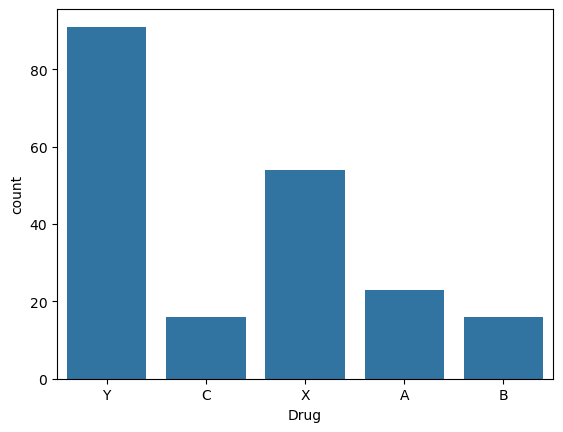

In [9]:
sns.countplot(data=data,x='Drug')

In [10]:
from sklearn.preprocessing import LabelEncoder

In [11]:
le = LabelEncoder()
data['Sex'] = le.fit_transform(data['Sex'])
data['BP'] = le.fit_transform(data['BP'])
data['Cholesterol'] = le.fit_transform(data['Cholesterol'])
data.head()

,Age,Sex,BP,Cholesterol,Salt,Drug
0,23,0,0,0,25.355,Y
1,47,1,1,0,13.093,C
2,47,1,1,0,10.114,C
3,28,0,2,0,7.798,X
4,61,0,1,0,18.043,Y


In [12]:
print(data['Sex' ].unique()) # 0 -female 1-male
print(data['BP'].unique()) # 0 - High 1 -low 2-normal
print(data['Cholesterol'].unique()) # 0 -high 1-low 

[0 1]
[0 1 2]
[0 1]


In [13]:
# separating X and Y data
x = data.drop(columns='Drug')
y = data['Drug']

In [14]:
x

,Age,Sex,BP,Cholesterol,Salt
0,23,0,0,0,25.355
1,47,1,1,0,13.093
2,47,1,1,0,10.114
3,28,0,2,0,7.798
4,61,0,1,0,18.043
...,...,...,...,...,...
195,56,0,1,0,11.567
196,16,1,1,0,12.006
197,52,1,2,0,9.894
198,23,1,2,1,14.020


In [15]:
y

0      Y
1      C
2      C
3      X
4      Y
      ..
195    C
196    C
197    X
198    X
199    X
Name: Drug, Length: 200, dtype: object

<Axes: >

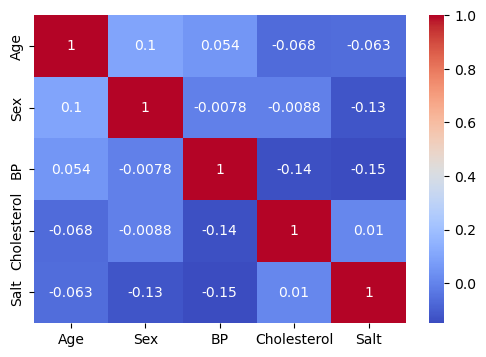

In [17]:
# Checking correlation between feature variables
plt.figure(figsize=(6,4))
sns.heatmap(x.corr(),cmap='coolwarm',annot=True,fmt = '.2g',linecolor='black')

In [18]:
#Create a Naive Bayes object
nb = GaussianNB()

In [19]:
# train-test-split

x_train, x_test, y_train, y_test = train_test_split(x, y,test_size=0.2, random_state=4)

In [20]:
x_train.shape

(160, 5)

In [21]:
x_test.shape

(40, 5)

In [22]:
nb.fit(x_train ,y_train)

,priors,None
,var_smoothing,1e-09


In [23]:
y_pred_test = nb.predict(x_test)

In [24]:
y_pred_test

array(['A', 'A', 'Y', 'B', 'C', 'X', 'Y', 'Y', 'Y', 'A', 'A', 'X', 'A',
       'Y', 'Y', 'Y', 'Y', 'X', 'A', 'C', 'X', 'C', 'A', 'X', 'C', 'B',
       'X', 'Y', 'X', 'Y', 'B', 'C', 'X', 'X', 'Y', 'Y', 'A', 'A', 'X',
       'Y'], dtype='<U1')

In [25]:
y_pred_train = nb.predict(x_train)

In [26]:
y_pred_train

array(['Y', 'Y', 'Y', 'C', 'Y', 'Y', 'Y', 'X', 'C', 'Y', 'A', 'Y', 'X',
       'Y', 'C', 'B', 'Y', 'C', 'C', 'Y', 'A', 'X', 'X', 'A', 'Y', 'A',
       'Y', 'Y', 'A', 'Y', 'Y', 'B', 'X', 'C', 'A', 'A', 'B', 'Y', 'A',
       'X', 'Y', 'A', 'Y', 'Y', 'X', 'X', 'Y', 'Y', 'Y', 'A', 'Y', 'B',
       'Y', 'X', 'A', 'A', 'X', 'C', 'C', 'A', 'Y', 'A', 'X', 'X', 'Y',
       'Y', 'X', 'A', 'X', 'B', 'A', 'X', 'Y', 'X', 'X', 'C', 'B', 'Y',
       'X', 'C', 'C', 'B', 'X', 'Y', 'Y', 'A', 'C', 'Y', 'A', 'Y', 'B',
       'X', 'X', 'A', 'X', 'Y', 'B', 'Y', 'X', 'Y', 'X', 'C', 'A', 'A',
       'X', 'B', 'X', 'Y', 'C', 'Y', 'Y', 'X', 'B', 'Y', 'X', 'C', 'X',
       'Y', 'A', 'X', 'X', 'A', 'Y', 'X', 'B', 'X', 'Y', 'A', 'C', 'B',
       'X', 'X', 'B', 'Y', 'C', 'Y', 'Y', 'Y', 'Y', 'B', 'X', 'X', 'Y',
       'Y', 'C', 'Y', 'X', 'C', 'C', 'Y', 'X', 'X', 'A', 'Y', 'C', 'Y',
       'X', 'A', 'A', 'Y'], dtype='<U1')

In [27]:
from sklearn.metrics import accuracy_score,classification_report, confusion_matrix

In [28]:
print(classification_report(y_train, y_pred_train))

              precision    recall  f1-score   support

           A       0.63      1.00      0.77        17
           B       0.87      1.00      0.93        13
           C       0.52      1.00      0.69        11
           X       1.00      0.95      0.98        43
           Y       0.96      0.71      0.82        76

    accuracy                           0.85       160
   macro avg       0.80      0.93      0.84       160
weighted avg       0.90      0.85      0.86       160



In [29]:
print(classification_report(y_test, y_pred_test))

              precision    recall  f1-score   support

           A       0.67      1.00      0.80         6
           B       0.67      0.67      0.67         3
           C       1.00      1.00      1.00         5
           X       1.00      0.91      0.95        11
           Y       0.92      0.80      0.86        15

    accuracy                           0.88        40
   macro avg       0.85      0.88      0.86        40
weighted avg       0.90      0.88      0.88        40



In [30]:
confusion_matrix(y_test,y_pred_test)

array([[ 6,  0,  0,  0,  0],
       [ 1,  2,  0,  0,  0],
       [ 0,  0,  5,  0,  0],
       [ 0,  0,  0, 10,  1],
       [ 2,  1,  0,  0, 12]])

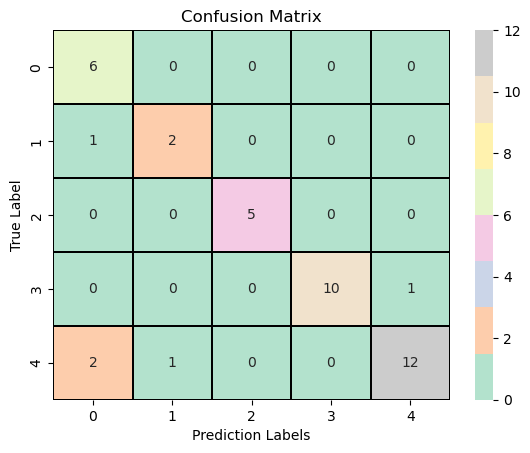

In [34]:
cm=confusion_matrix(y_test,y_pred_test)
sns.heatmap(cm, annot=True, linewidths=0.3,linecolor='black',cmap='Pastel2',fmt='d')
plt.xlabel('Prediction Labels')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

In [35]:
# Displaying confusion matrix with original target vo
from sklearn.metrics import ConfusionMatrixDisplay
category_names = ['A', 'B', 'C', 'X', 'Y'] # drug co
disp = ConfusionMatrixDisplay(confusion_matrix = cm)

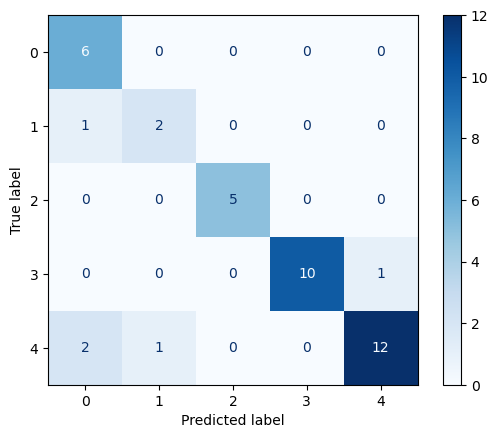

In [37]:
display_labels=category_names
disp.plot(cmap=plt.cm.Blues)
plt.show()

In [38]:
# Testing the algorithm output
# Age , Sex, BP, Cholesterol, Salt
nb.predict([[21,0,2,1, 10]])

array(['X'], dtype='<U1')

In [39]:
nb.predict([[21,0,2,1,55]])

array(['Y'], dtype='<U1')

In [ ]:
-In today's class we have learned naive bayes's theorem in this ,firstly we have done LableEncoder 
then make feature such as sex, BP, Cholesterol in range 1 to 2 
then we checked correlation between features after that
trained the model 
then we come to know that those who have more salt ,machine suggest Y drugs and those who have less salt ,machine suggest X drugs

